<a href="https://colab.research.google.com/github/joshirdzdel-svg/estadisticainferencial2026A/blob/main/practica_1_Unidad%203%20.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Práctica 01 para series de tiempo

Para esta práctica, se utilizará la librería `yfinance`, la cual permite obtener datos históricos de mercados financieros directamente desde Yahoo Finance. Esta herramienta es de uso gratuito y no requiere el uso de claves de acceso (API keys), lo que la hace especialmente conveniente para fines educativos.

Los datos obtenidos mediante `yfinance` corresponden a información real del mercado financiero. Sin embargo, es importante considerar que esta herramienta no constituye una fuente oficial de datos, por lo que puede presentar limitaciones en cuanto a disponibilidad, consistencia o actualización. Para fines académicos y de análisis exploratorio, estos datos son adecuados; no obstante, para aplicaciones profesionales o decisiones financieras, se recomienda el uso de fuentes oficiales o servicios especializados.

Adicionalmente, `yfinance` no es una API oficial, por lo que en ocasiones puede presentar fallas temporales en la descarga de datos.

Los principales argumentos que requiere yfinance para realizar la descarga son:

+ `tickers`: Los tickers son identificadores únicos de activos financieros (por ejemplo, acciones) en los mercados. Por ejemplo, `AAPL` corresponde a Apple, `TSLA` a Tesla y `MSFT` a Microsoft. Si quieres inspeccionar tickers [pulsa aquí](https://www.nasdaq.com/market-activity/stocks/screener) y se te abrirá un catálogo de diversas multinacionales.
+ `start`: Fecha de inicio para la descarga de datos en formato `YYYY-mm-dd` que significa: cuatro dígitos para el año (`YYYY`), dos dígitos para el mes (`mm`) y dos dígitos para el día (`dd`) en ese orden.
+ `end`: Fecha de fin para la descarga de datos siguiendo también un formato `YYYY-mm-dd`.
+ `interval`: Define la frecuencia de los datos. Por ejemplo, `"1d"` indica datos diarios, `"1wk"` semanales y `"1mo"` mensuales.
+ `group_by`: Define la forma en que se organizan las columnas cuando se descargan datos de uno o varios tickers. Por ejemplo, `group_by="column"` organiza la información por tipo de variable (Open, High, Low, Close, etc.), mientras que `group_by="ticker"` agrupa primero por activo financiero.
+ `auto_adjust`: Si se establece en `True`, los precios se ajustan automáticamente considerando dividendos y divisiones de acciones. Si es `False`, se mantienen los valores originales.
+ `actions`: Permite incluir información adicional como dividendos y divisiones de acciones cuando se establece en `True`.
+ `progress`: Controla si se muestra o no una barra de progreso durante la descarga.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
import warnings
warnings.filterwarnings("ignore")

# Link para inspeccionar tickers:
# https://www.nasdaq.com/market-activity/stocks/screener

# Obtener datos de acciones
df = yf.download(
    tickers="AAPL",          # AAPL: Apple, TSLA: Tesla, MSFT: Microsoft, etc.
    start="2024-01-01",      # Fecha de inicio
    end="2026-04-01",        # Fecha de fin
    interval="1d",           # Intervalo de tiempo: 1 día
    group_by="column",       # Forma estándar de organizar las columnas
    auto_adjust=False,       # False conserva columnas como Close y Adj Close
    actions=False,           # True incluiría dividendos y divisiones de acciones
    progress=False           # Evita mostrar barra de progreso
)

# Verificar si la descarga fue exitosa
if df.empty:
    raise ValueError(
        "No se descargaron datos. Verifica que el ticker sea correcto "
        "o intenta nuevamente más tarde."
    )

# Paso 1: Mover 'Date' del índice a columna regular
df = df.reset_index()

# Paso 2: Aplanar columnas si vienen como MultiIndex
# Esto puede ocurrir dependiendo de la versión de yfinance/pandas.
if isinstance(df.columns, pd.MultiIndex):
    df.columns = [
        "_".join([str(valor) for valor in columna if valor != ""]).strip()
        for columna in df.columns
    ]

# Reemplazar espacios por _
df.columns = [i.replace(" ", "_") for i in df.columns]

# Paso 3:
#######################################################
## En caso de que no se requiera la hora

# Convertir la columna 'Date' a tipo datetime
df['Date'] = pd.to_datetime(df['Date'], format='%Y-%m-%d')

df

,Date,Adj_Close_AAPL,Close_AAPL,High_AAPL,Low_AAPL,Open_AAPL,Volume_AAPL
0,2024-01-02,183.404037,185.639999,188.440002,183.889999,187.149994,82488700
1,2024-01-03,182.030746,184.250000,185.880005,183.429993,184.220001,58414500
2,2024-01-04,179.718933,181.910004,183.089996,180.880005,182.149994,71983600
3,2024-01-05,178.997757,181.179993,182.759995,180.169998,181.990005,62379700
4,2024-01-08,183.324982,185.559998,185.600006,181.500000,182.089996,59144500
...,...,...,...,...,...,...,...
558,2026-03-25,252.169983,252.619995,255.000000,251.600006,254.100006,28476700
559,2026-03-26,252.439514,252.889999,257.000000,250.770004,252.119995,41796700
560,2026-03-27,248.356796,248.800003,255.490005,248.070007,253.899994,47900000
561,2026-03-30,246.190659,246.630005,250.869995,245.509995,250.070007,39446200


Una vez extraida la información, tenemos un DataFrame con las siguientes variables:

+ `Date`: Fecha correspondiente a cada registro de la serie de tiempo.
+ `Open_AAPL`: Precio de apertura de la acción al inicio de la jornada.
+ `High_AAPL`: Precio máximo alcanzado por la acción durante el intervalo de tiempo seleccionado.
+ `Low_AAPL`: Precio mínimo registrado durante el intervalo de tiempo seleccionado.
+ `Close_AAPL`: Precio de cierre de la acción al final del intervalo de tiempo seleccionado.
+ `Adj_Close_AAPL`: Precio de cierre ajustado, el cual incorpora efectos de dividendos y divisiones de acciones, proporcionando una medida más consistente para análisis históricos.
+ `Volume_AAPL`: Número total de acciones negociadas durante el día (volumen de transacciones).

En las series de tiempo `x` siempre es la variable temporal, en esta caso `Date`, mientras que `y` puede ser cualquiera de las restantes, dependiendo de lo que se esté analizando. En este caso recomiendo usar `Adj_Close_APPL` debido a que es la que incorpora más información.

Primero se debe revisar el DataFrame para asegurarnos de que las variables son del tipo adecuado (sin variables tipo `object`).

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 563 entries, 0 to 562
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   Date            563 non-null    datetime64[ns]
 1   Adj_Close_AAPL  563 non-null    float64       
 2   Close_AAPL      563 non-null    float64       
 3   High_AAPL       563 non-null    float64       
 4   Low_AAPL        563 non-null    float64       
 5   Open_AAPL       563 non-null    float64       
 6   Volume_AAPL     563 non-null    int64         
dtypes: datetime64[ns](1), float64(5), int64(1)
memory usage: 30.9 KB


Ahora se declara `x` y `y`.

In [ ]:
x = df["Date"]
y = df['Adj_Close_AAPL']

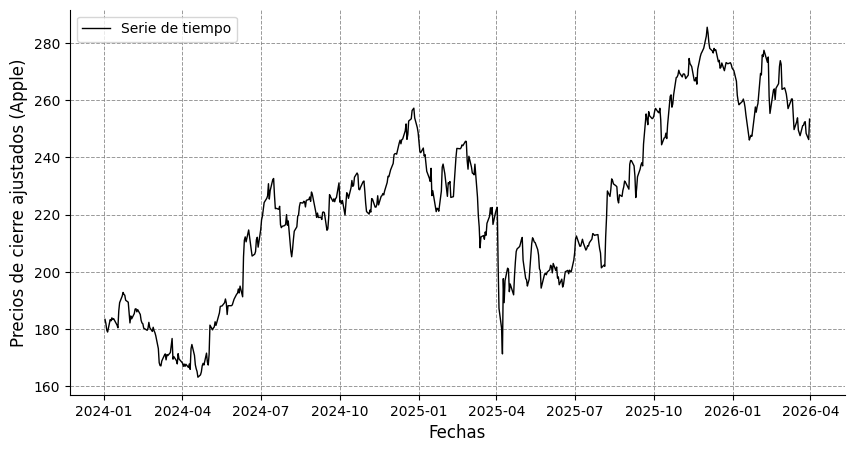

In [ ]:
# @title
import matplotlib.pyplot as plt

# --- Configuración general del gráfico ---
plt.figure(
    figsize=(10, 5),   # tamaño de la figura (ancho, alto) en pulgadas
    dpi=100           # resolución del gráfico
)

# --- Gráfico de línea ---
plt.plot(
    x, y,
    color='black',   # color de la línea
    linewidth=1.0,        # grosor de la línea
    linestyle='-',        # estilo de línea
    marker='o',           # marcador en cada punto
    markersize=0,         # tamaño del marcador
    markerfacecolor='white',
    markeredgecolor='black',
    label='Serie de tiempo'
)

# --- Título ---
plt.title(
    '',
    fontsize=14,
    fontweight='bold'
)

# --- Etiquetas de los ejes ---
plt.xlabel(
    'Fechas',
    fontsize=12
)

plt.ylabel(
    'Precios de cierre ajustados (Apple)',
    fontsize=12
)

# --- Fuente de los ticks ---
plt.xticks(fontsize=10)
plt.yticks(fontsize=10)

# --- Márgenes ---
plt.margins(x=0.05, y=0.05)  # espacio extra alrededor de los datos
plt.gca().spines['right'].set_visible(False) # derecha
plt.gca().spines['top'].set_visible(False)   # superior

# Para eliminar márgenes completamente, usar:
# plt.margins(0)

# --- Cuadrícula (opcional, pero didáctica) ---
plt.grid(
    visible=True,
    linestyle='--',
    linewidth=0.7,
    alpha=0.8,
    color="gray"
)

# --- Leyenda ---
plt.legend(
    fontsize=10,
    loc='best',
    frameon=True
)



## Métodos de promedios móviles

**Ejercicio 1**: Aplica una media móvil simple (SMA) a la serie de tiempo. Prueba con distintos tamaños de ventana (`window`) y selecciona uno que consideres adecuado. Justifica tu elección con base en el comportamiento observado en la serie.

Ten en cuenta que la serie de tiempo no incluye sábados ni domingos; por lo tanto, aproximadamente:

+ 5 observaciones corresponden a una semana
+ 21 observaciones a un mes
+ 252 observaciones a un año

Una vez termines, borra estas instrucciones y redacta tus observaciones.


## Método de suavisación exponencial

**Ejercicio 2**: Aplica una suavización exponencial simple (SES) a la serie de tiempo. Prueba con distintos valores del parámetro de suavizamiento (por ejemplo, mediante span o alpha) y selecciona uno que consideres adecuado. Justifica tu elección con base en el comportamiento observado en la serie.

Ten en cuenta que la serie de tiempo no incluye sábados ni domingos; por lo tanto, aproximadamente:

+ 5 observaciones corresponden a una semana
+ 21 observaciones a un mes
+ 252 observaciones a un año

Una vez termines, borra estas instrucciones y redacta tus observaciones.

**Ejercicio 3**: Observando las curvas por SMA y SES, señala las ventajas y desventajas que puedes observar en ambos gráficos.

Una vez termines, borra estas instrucciones y redacta tus observaciones.

## Tendencias no lineales

**Ejercicio 4**: Realiza una regresión polinomial de grado 2. Usa series de Fourier para extraer la estacionalidad y calcular el ruido de medición. Apóyate en los gráficos correspondientes y analiza las longitudes de onda para establecer si existe estacionalidad. Ten en cuenta que la serie de tiempo no incluye sábados ni domingos; por lo tanto, aproximadamente:

+ 5 observaciones corresponden a una semana
+ 21 observaciones a un mes
+ 252 observaciones a un año

Una vez termines, borra estas instrucciones y redacta tus observaciones.

## Análisis de los componentes de la serie

**Ejercicio 5**: Apóyate de los gráficos correspondientes para analizar cada uno de los componentes de la serie por separado. Comenta lo que se puede observar de cada componente, si crees que se pudo aproximar bien o no, y por qué.

Una vez termines, borra estas instrucciones y redacta tus observaciones.

## Análisis fundamental (ligero)

**Ejercicio 6**: Realiza una interpretación de los componentes de la serie de tiempo (tendencia, estacionalidad y ruido).

En tu análisis:

+ Explica qué factores externos podrían justificar la tendencia observada (por ejemplo: crecimiento de la empresa, cambios en el mercado, decisiones estratégicas, etc.).
+ Identifica posibles eventos o situaciones que expliquen los patrones de estacionalidad.
+ Reflexiona sobre el ruido, indicando qué tipo de eventos inesperados o aleatorios podrían estar representados en este componente.

Este análisis no requiere un estudio exhaustivo del entorno económico, pero sí una interpretación razonada, similar a un análisis fundamental básico.

Una vez termines, borra estas instrucciones y redacta tus observaciones.

## Aplicaciones

**Ejercicio 7**: Analiza qué personas, empresas o instituciones podrían beneficiarse del análisis realizado.

En tu respuesta:

+ Menciona al menos tres actores (por ejemplo: inversionistas, empresas, instituciones financieras, gobierno, etc.).
+ Explica cómo utilizarían este tipo de análisis.
+ Describe qué beneficios concretos podrían obtener.

Adicionalmente, reflexiona sobre cómo un análisis más profundo podría mejorar estos beneficios o ampliar sus aplicaciones.

Relaciona tu respuesta con los resultados obtenidos en tu análisis (tendencia, estacionalidad y ruido).

Una vez termines, borra estas instrucciones y redacta tus observaciones.

In [ ]:

import pandas as pd
link_csv = "https://raw.githubusercontent.com/joshirdzdel-svg/estadisticainferencial2026A/refs/heads/main/Unidad_03/Practica_01/nasdaq_screener_1792638510409.csv"
df = pd.read_csv(link_csv)
df

,Symbol,Name,Last Sale,Net Change,% Change,Market Cap,Country,IPO Year,Volume,Sector,Industry
0,A,Agilent Technologies Inc. Common Stock,$173.01,3.1100,1.83%,4.877651e+10,United States,1999.0,1978715,Industrials,Biotechnology: Laboratory Analytical Instruments
1,AA,Alcoa Corporation Common Stock,$40.79,-0.8800,-2.112%,1.076487e+10,United States,2016.0,5743983,Industrials,Aluminum
2,AAC,Ares Acquisition Corporation III Class A Ordin...,$9.97,-0.0090,-0.09%,4.927049e+08,NaN,2026.0,40139,Industrials,Metal Fabrications
3,AACG,ATA Creativity Global American Depositary Shares,$0.6575,-0.1325,-16.772%,4.501509e+07,China,2008.0,11213,Real Estate,Other Consumer Services
4,AACI,Armada Acquisition Corp. III Class A Ordinary ...,$10.06,0.0000,0.00%,0.000000e+00,United States,2026.0,100,Finance,Blank Checks
...,...,...,...,...,...,...,...,...,...,...,...
6951,ZVIA,Zevia PBC Class A Common Stock,$1.22,0.0000,0.00%,9.436139e+07,United States,2021.0,163853,Consumer Staples,Beverages (Production/Distribution)
6952,ZVRA,Zevra Therapeutics Inc. Common Stock,$10.47,0.3100,3.051%,6.217482e+08,United States,NaN,432272,Health Care,Biotechnology: Pharmaceutical Preparations
6953,ZWS,Zurn Elkay Water Solutions Corporation Common ...,$47.71,0.5900,1.252%,7.913376e+09,United States,2012.0,673431,Industrials,Industrial Machinery/Components
6954,ZYBT,Zhengye Biotechnology Holding Limited Class A ...,$1.49,0.0400,2.759%,7.061315e+07,China,2025.0,17564,Health Care,Biotechnology: Pharmaceutical Preparations


In [ ]:
df.drop(columns=["Symbol",
                 "Name"], inplace=True)
df

,Last Sale,Net Change,% Change,Market Cap,Country,IPO Year,Volume,Sector,Industry
0,$173.01,3.1100,1.83%,4.877651e+10,United States,1999.0,1978715,Industrials,Biotechnology: Laboratory Analytical Instruments
1,$40.79,-0.8800,-2.112%,1.076487e+10,United States,2016.0,5743983,Industrials,Aluminum
2,$9.97,-0.0090,-0.09%,4.927049e+08,NaN,2026.0,40139,Industrials,Metal Fabrications
3,$0.6575,-0.1325,-16.772%,4.501509e+07,China,2008.0,11213,Real Estate,Other Consumer Services
4,$10.06,0.0000,0.00%,0.000000e+00,United States,2026.0,100,Finance,Blank Checks
...,...,...,...,...,...,...,...,...,...
6951,$1.22,0.0000,0.00%,9.436139e+07,United States,2021.0,163853,Consumer Staples,Beverages (Production/Distribution)
6952,$10.47,0.3100,3.051%,6.217482e+08,United States,NaN,432272,Health Care,Biotechnology: Pharmaceutical Preparations
6953,$47.71,0.5900,1.252%,7.913376e+09,United States,2012.0,673431,Industrials,Industrial Machinery/Components
6954,$1.49,0.0400,2.759%,7.061315e+07,China,2025.0,17564,Health Care,Biotechnology: Pharmaceutical Preparations


In [ ]:

from numpy import column_stack
df = df. rename (columns = {
   "Last Sale":"Ultima_venta",
   "Net Change":"Cambio_neto",
   "% Change":"Cambio_%",
   "Market Cap":"Capitalizacion_de_mercado",
   "Country":"Pais",
   "IPO Year":"Ano_de_IPO",
   "Volume":"Volumen",
   "Sector":"Sector",
   "Industry":"Industria"
})
df

,Ultima_venta,Cambio_neto,Cambio_%,Capitalizacion_de_mercado,Pais,Ano_de_IPO,Volumen,Sector,Industria
0,$173.01,3.1100,1.83%,4.877651e+10,United States,1999.0,1978715,Industrials,Biotechnology: Laboratory Analytical Instruments
1,$40.79,-0.8800,-2.112%,1.076487e+10,United States,2016.0,5743983,Industrials,Aluminum
2,$9.97,-0.0090,-0.09%,4.927049e+08,NaN,2026.0,40139,Industrials,Metal Fabrications
3,$0.6575,-0.1325,-16.772%,4.501509e+07,China,2008.0,11213,Real Estate,Other Consumer Services
4,$10.06,0.0000,0.00%,0.000000e+00,United States,2026.0,100,Finance,Blank Checks
...,...,...,...,...,...,...,...,...,...
6951,$1.22,0.0000,0.00%,9.436139e+07,United States,2021.0,163853,Consumer Staples,Beverages (Production/Distribution)
6952,$10.47,0.3100,3.051%,6.217482e+08,United States,NaN,432272,Health Care,Biotechnology: Pharmaceutical Preparations
6953,$47.71,0.5900,1.252%,7.913376e+09,United States,2012.0,673431,Industrials,Industrial Machinery/Components
6954,$1.49,0.0400,2.759%,7.061315e+07,China,2025.0,17564,Health Care,Biotechnology: Pharmaceutical Preparations


In [ ]:
df = df[(df["Cambio_neto"]>=0) &(df["Cambio_neto"]<=2)]


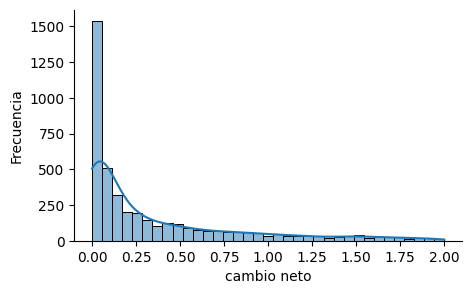

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Histograma
plt.figure(
    figsize=(5,3),
    dpi = 100
)
sns.histplot(df['Cambio_neto'], kde=True)
plt.xlabel("cambio neto")
plt.ylabel("Frecuencia")
plt.gca().spines[["top", "right"]].set_visible(False)
plt.show()

In [ ]:
df = df[(df["Capitalizacion_de_mercado"]>=1) &(df["Capitalizacion_de_mercado"]<=3.7799e+09)]


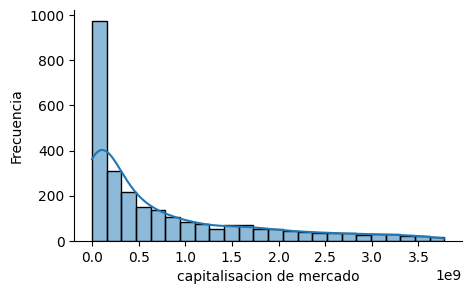

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Histograma
plt.figure(
    figsize=(5,3),
    dpi = 100
)
sns.histplot(df['Capitalizacion_de_mercado'], kde=True)
plt.xlabel("capitalisacion de mercado")
plt.ylabel("Frecuencia")
plt.gca().spines[["top", "right"]].set_visible(False)
plt.show()

In [ ]:
df = df[(df["Ano_de_IPO"]>=1990) &(df["Ano_de_IPO"]<=2026)]


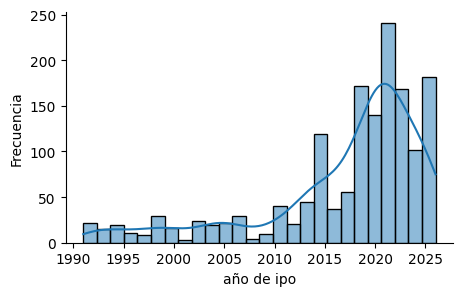

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Histograma
plt.figure(
    figsize=(5,3),
    dpi = 100
)
sns.histplot(df['Ano_de_IPO'], kde=True)
plt.xlabel("año de ipo")
plt.ylabel("Frecuencia")
plt.gca().spines[["top", "right"]].set_visible(False)
plt.show()

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1554 entries, 9 to 6954
Data columns (total 9 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Ultima_venta               1554 non-null   object 
 1   Cambio_neto                1554 non-null   float64
 2   Cambio_%                   1554 non-null   object 
 3   Capitalizacion_de_mercado  1554 non-null   float64
 4   Pais                       1454 non-null   object 
 5   Ano_de_IPO                 1554 non-null   float64
 6   Volumen                    1554 non-null   int64  
 7   Sector                     1542 non-null   object 
 8   Industria                  1542 non-null   object 
dtypes: float64(3), int64(1), object(5)
memory usage: 121.4+ KB


In [ ]:
df.describe ()

,Cambio_neto,Capitalizacion_de_mercado,Ano_de_IPO,Volumen
count,1554.000000,1.554000e+03,1554.000000,1.554000e+03
mean,0.291092,7.794082e+08,2017.005148,1.356168e+06
std,0.389093,9.427550e+08,8.178622,1.137837e+07
min,0.000000,4.837000e+03,1991.000000,6.000000e+00
25%,0.030000,6.188985e+07,2014.000000,5.264500e+04
50%,0.130000,3.892452e+08,2020.000000,2.480685e+05
75%,0.387500,1.189668e+09,2022.000000,8.978100e+05
max,1.960000,3.760322e+09,2026.000000,4.215608e+08


In [ ]:
df = df[(df["Volumen"]>=6) &(df["Volumen"]<=8.9781e+05)]


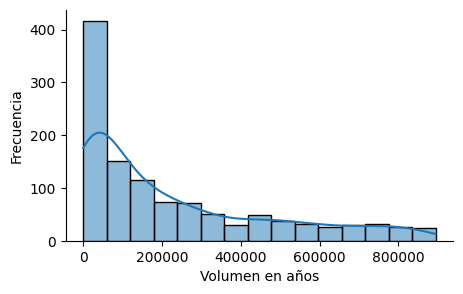

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Histograma
plt.figure(
    figsize=(5,3),
    dpi = 100
)
sns.histplot(df["Volumen"], kde=True)
plt.xlabel("Volumen en años")
plt.ylabel("Frecuencia")
plt.gca().spines[["top", "right"]].set_visible(False)
plt.show()

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Crear una copia de los datos
df = df.copy()

# Convertir precio de última venta a número
df["Ultima_venta"] = pd.to_numeric(
    df["Ultima_venta"].astype(str)
    .str.replace("$", "", regex=False)
    .str.replace(",", "", regex=False),
    errors="coerce"
)

# Convertir cambio porcentual a número
df["Cambio_%"] = pd.to_numeric(
    df["Cambio_%"].astype(str)
    .str.replace("%", "", regex=False)
    .str.replace(",", "", regex=False),
    errors="coerce"
)

# Revisar los datos
display(df.head())
df.info()

,Ultima_venta,Cambio_neto,Cambio_%,Capitalizacion_de_mercado,Pais,Ano_de_IPO,Volumen,Sector,Industria
12,94.360,1.160,1.245,3.348848e+09,United Kingdom,2014.0,355620,Finance,Investment Managers
16,15.920,0.560,3.646,1.485822e+09,China,2025.0,4897,Health Care,Biotechnology: Pharmaceutical Preparations
18,3.900,0.160,4.278,8.535090e+07,United States,2025.0,66710,Health Care,Biotechnology: Pharmaceutical Preparations
19,20.750,0.130,0.630,1.274137e+09,United States,2011.0,391594,Real Estate,Real Estate Investment Trusts
33,2.015,0.245,13.842,1.457193e+08,United States,2021.0,784646,Health Care,Biotechnology: Biological Products (No Diagnos...


<class 'pandas.core.frame.DataFrame'>
Index: 1165 entries, 12 to 6954
Data columns (total 9 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Ultima_venta               1165 non-null   float64
 1   Cambio_neto                1165 non-null   float64
 2   Cambio_%                   1165 non-null   float64
 3   Capitalizacion_de_mercado  1165 non-null   float64
 4   Pais                       1079 non-null   object 
 5   Ano_de_IPO                 1165 non-null   float64
 6   Volumen                    1165 non-null   int64  
 7   Sector                     1153 non-null   object 
 8   Industria                  1153 non-null   object 
dtypes: float64(5), int64(1), object(3)
memory usage: 91.0+ KB


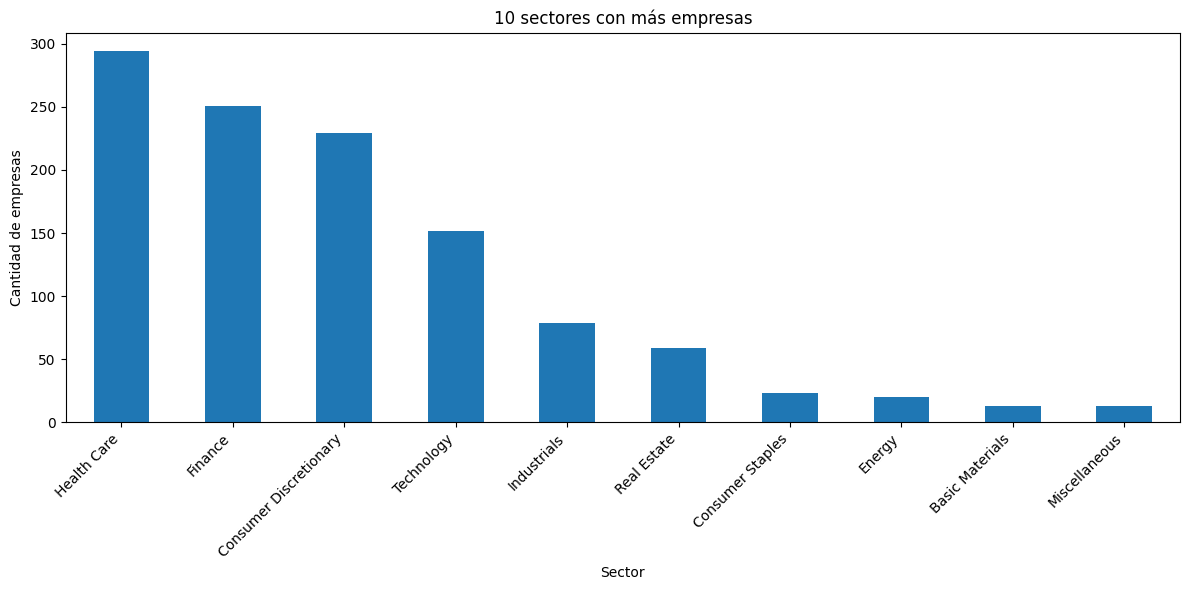

In [ ]:
plt.figure(figsize=(12, 6))

df["Sector"].value_counts().head(10).plot(kind="bar")

plt.title("10 sectores con más empresas")
plt.xlabel("Sector")
plt.ylabel("Cantidad de empresas")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

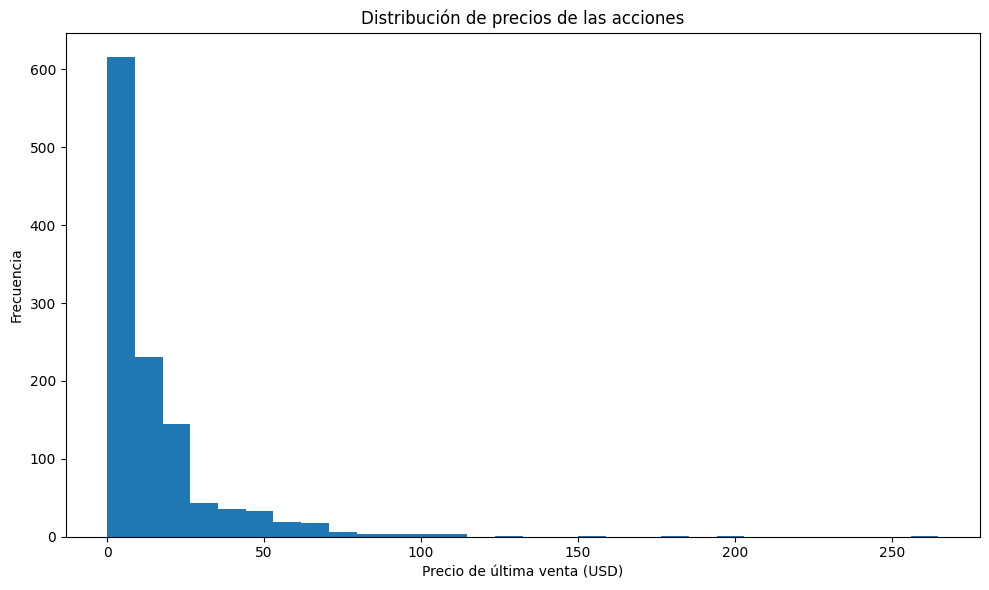

In [ ]:
plt.figure(figsize=(10, 6))

plt.hist(df["Ultima_venta"].dropna(), bins=30)

plt.title("Distribución de precios de las acciones")
plt.xlabel("Precio de última venta (USD)")
plt.ylabel("Frecuencia")
plt.tight_layout()
plt.show()

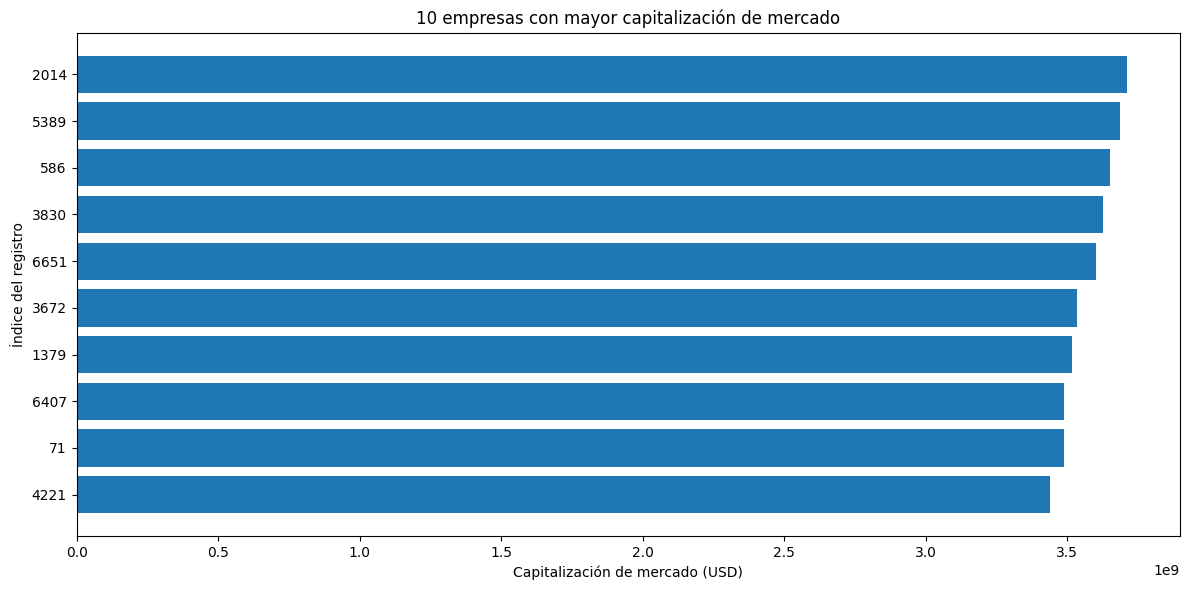

In [ ]:
top_empresas = df.nlargest(
    10, "Capitalizacion_de_mercado"
).sort_values("Capitalizacion_de_mercado")

plt.figure(figsize=(12, 6))

plt.barh(
    top_empresas.index.astype(str),
    top_empresas["Capitalizacion_de_mercado"]
)

plt.title("10 empresas con mayor capitalización de mercado")
plt.xlabel("Capitalización de mercado (USD)")
plt.ylabel("Índice del registro")
plt.ticklabel_format(axis="x", style="sci", scilimits=(0, 0))
plt.tight_layout()
plt.show()

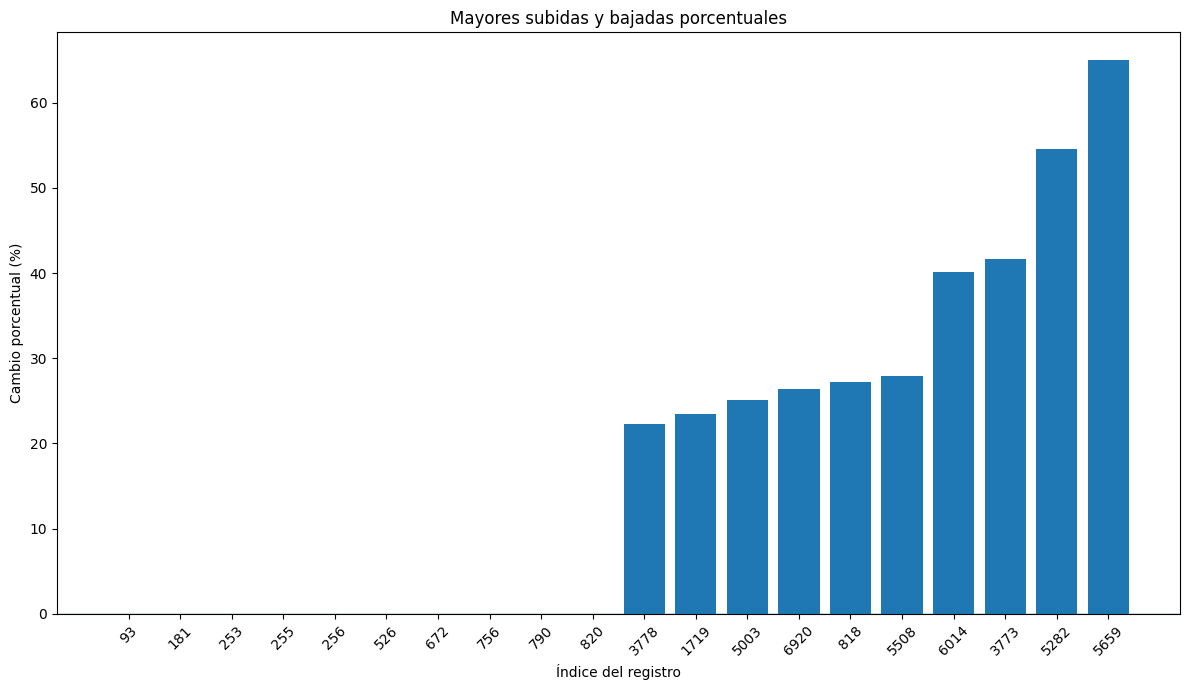

In [ ]:
subidas = df.nlargest(10, "Cambio_%")
bajadas = df.nsmallest(10, "Cambio_%")

variaciones = pd.concat([bajadas, subidas]).drop_duplicates()
variaciones = variaciones.sort_values("Cambio_%")

plt.figure(figsize=(12, 7))

plt.bar(
    variaciones.index.astype(str),
    variaciones["Cambio_%"]
)

plt.axhline(0, linewidth=1)
plt.title("Mayores subidas y bajadas porcentuales")
plt.xlabel("Índice del registro")
plt.ylabel("Cambio porcentual (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

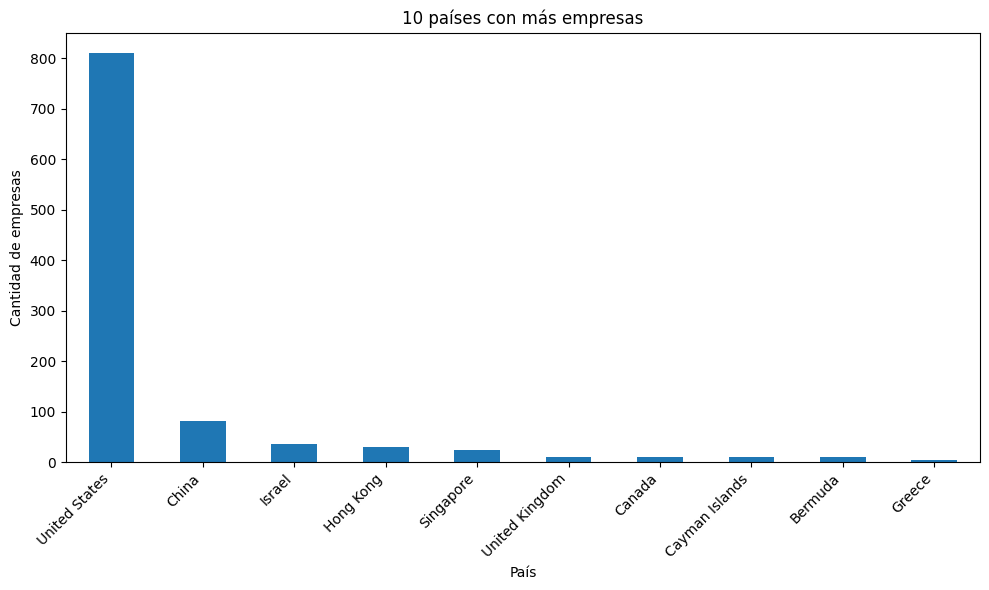

In [ ]:
plt.figure(figsize=(10, 6))

df["Pais"].value_counts().head(10).plot(kind="bar")

plt.title("10 países con más empresas")
plt.xlabel("País")
plt.ylabel("Cantidad de empresas")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

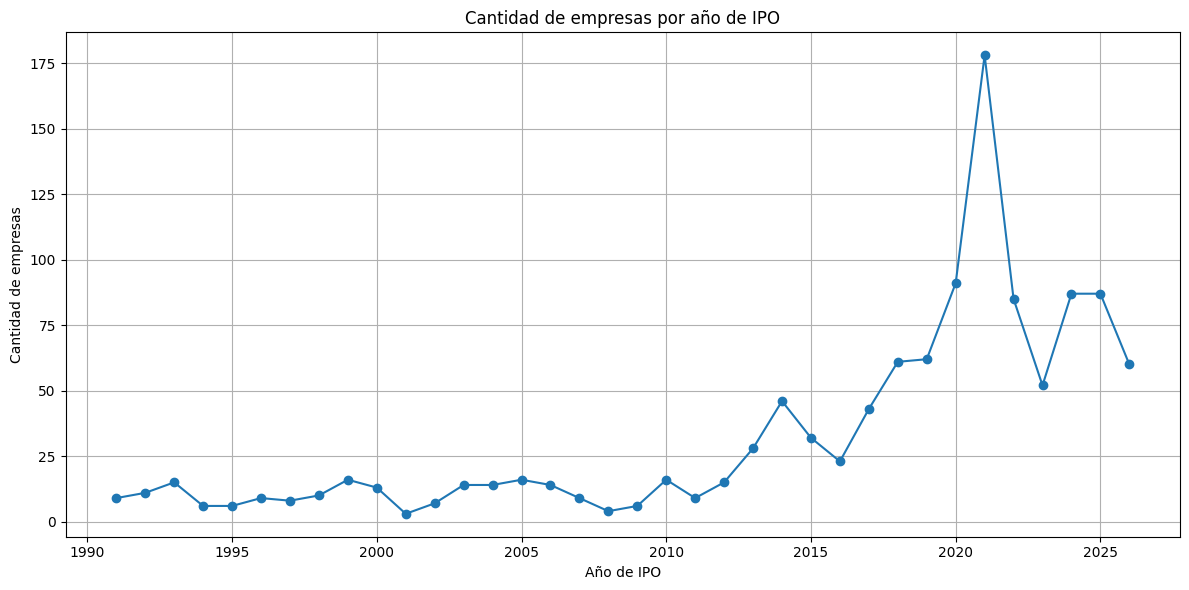

In [ ]:
ipo = df["Ano_de_IPO"].value_counts().sort_index()

plt.figure(figsize=(12, 6))

ipo.plot(kind="line", marker="o")

plt.title("Cantidad de empresas por año de IPO")
plt.xlabel("Año de IPO")
plt.ylabel("Cantidad de empresas")
plt.grid(True)
plt.tight_layout()
plt.show()

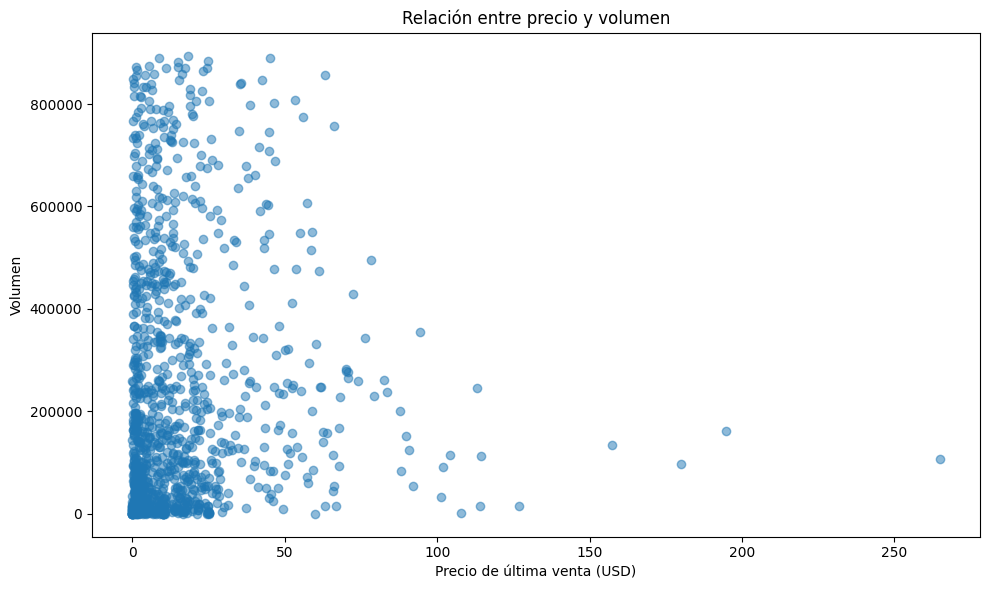

In [ ]:
plt.figure(figsize=(10, 6))

plt.scatter(
    df["Ultima_venta"],
    df["Volumen"],
    alpha=0.5
)

plt.title("Relación entre precio y volumen")
plt.xlabel("Precio de última venta (USD)")
plt.ylabel("Volumen")
plt.tight_layout()
plt.show()

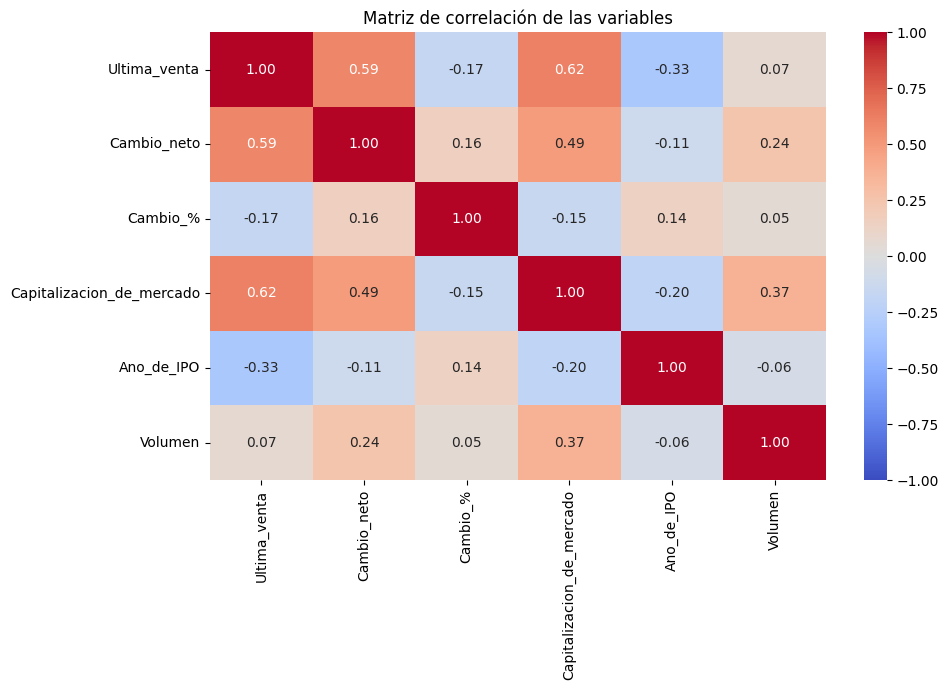

In [ ]:
variables = [
    "Ultima_venta",
    "Cambio_neto",
    "Cambio_%",
    "Capitalizacion_de_mercado",
    "Ano_de_IPO",
    "Volumen"
]

correlacion = df[variables].corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlacion,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Matriz de correlación de las variables")
plt.tight_layout()
plt.show()

In [ ]:
df_object = df.select_dtypes(include=["object"])

print(df_object.dtypes)

Pais         object
Sector       object
Industria    object
dtype: object


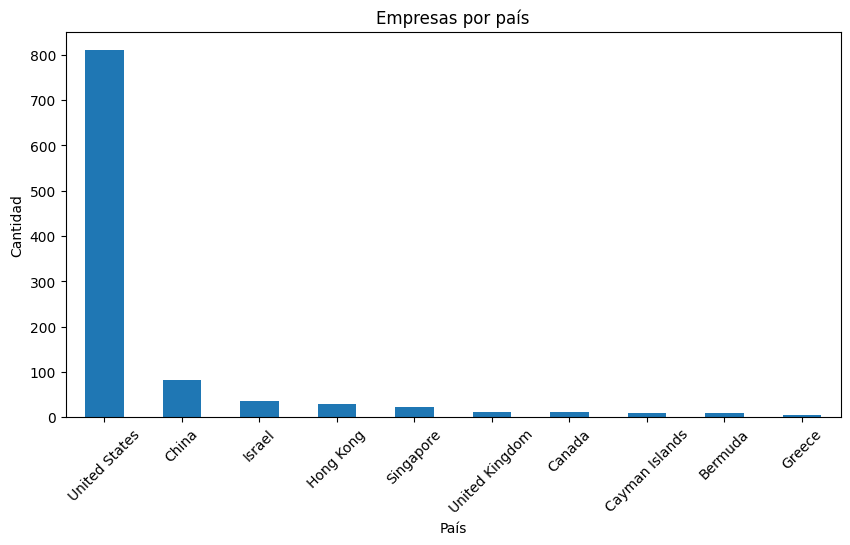

In [ ]:
df_object["Pais"].value_counts().head(10).plot(kind="bar", figsize=(10,5))

plt.title("Empresas por país")
plt.xlabel("País")
plt.ylabel("Cantidad")
plt.xticks(rotation=45)
plt.show()

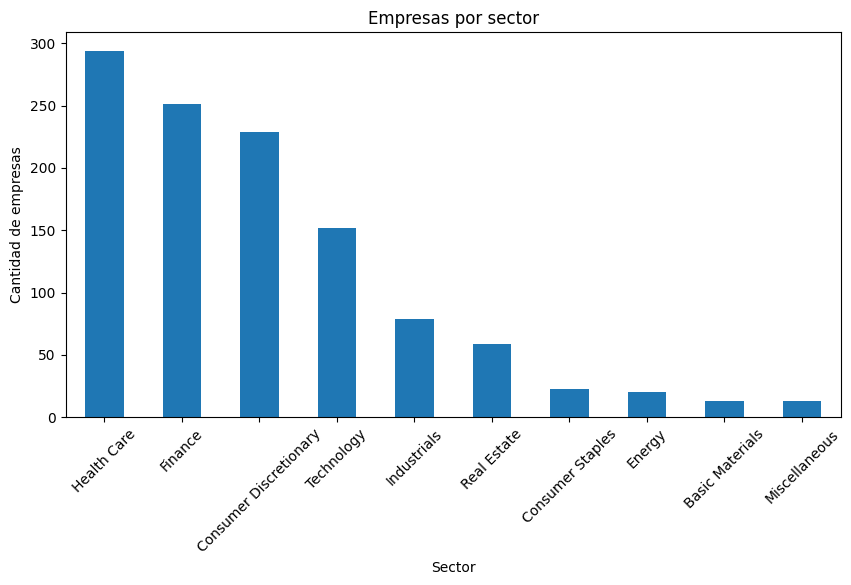

In [ ]:
df_object["Sector"].value_counts().head(10).plot(kind="bar", figsize=(10,5))

plt.title("Empresas por sector")
plt.xlabel("Sector")
plt.ylabel("Cantidad de empresas")
plt.xticks(rotation=45)
plt.show()

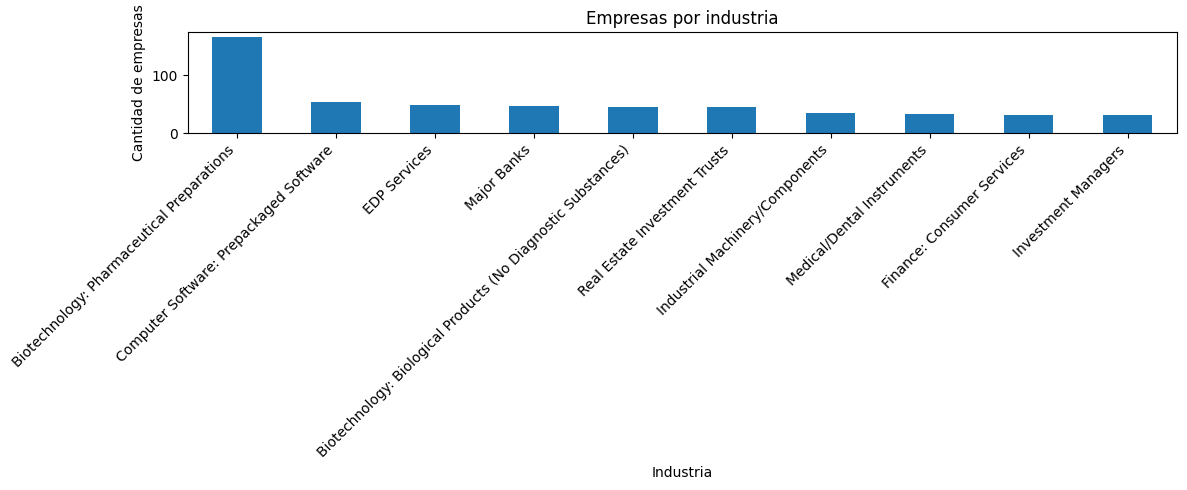

In [ ]:
df_object["Industria"].value_counts().head(10).plot(kind="bar", figsize=(12,5))

plt.title("Empresas por industria")
plt.xlabel("Industria")
plt.ylabel("Cantidad de empresas")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

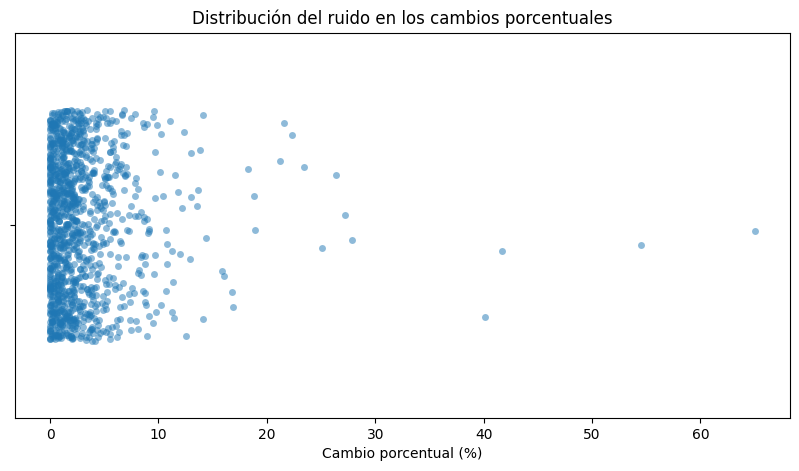

In [ ]:
plt.figure(figsize=(10,5))

sns.stripplot(
    x=ruido,
    jitter=0.3,
    alpha=0.5
)

plt.title("Distribución del ruido en los cambios porcentuales")
plt.xlabel("Cambio porcentual (%)")
plt.show()

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
import warnings
warnings.filterwarnings("ignore")

# Link para inspeccionar tickers:
# https://www.nasdaq.com/market-activity/stocks/screener

# Obtener datos de acciones
df = yf.download(
    tickers="LLY",          # LLY: Eli Lilly and Company Common Stock.
    start="2023-01-01",      # Fecha de inicio
    end="2026-04-01",        # Fecha de fin
    interval="1d",           # Intervalo de tiempo: 1 día
    group_by="column",       # Forma estándar de organizar las columnas
    auto_adjust=False,       # False conserva columnas como Close y Adj Close
    actions=False,           # True incluiría dividendos y divisiones de acciones
    progress=False           # Evita mostrar barra de progreso
)

# Verificar si la descarga fue exitosa
if df.empty:
    raise ValueError(
        "No se descargaron datos. Verifica que el ticker sea correcto "
        "o intenta nuevamente más tarde."
    )

# Paso 1: Mover 'Date' del índice a columna regular
df = df.reset_index()

# Paso 2: Aplanar columnas si vienen como MultiIndex
# Esto puede ocurrir dependiendo de la versión de yfinance/pandas.
if isinstance(df.columns, pd.MultiIndex):
    df.columns = [
        "_".join([str(valor) for valor in columna if valor != ""]).strip()
        for columna in df.columns
    ]

# Reemplazar espacios por _
df.columns = [i.replace(" ", "_") for i in df.columns]

# Paso 3:
#######################################################
## En caso de que no se requiera la hora

# Convertir la columna 'Date' a tipo datetime
df['Date'] = pd.to_datetime(df['Date'], format='%Y-%m-%d')

df

,Date,Adj_Close_LLY,Close_LLY,High_LLY,Low_LLY,Open_LLY,Volume_LLY
0,2023-01-03,354.709290,364.989990,369.000000,361.459991,366.260010,2006700
1,2023-01-04,352.872559,363.100006,367.119995,360.339996,364.640015,1886200
2,2023-01-05,348.810333,358.920013,361.489990,352.959991,360.950012,2008500
3,2023-01-06,352.717010,362.940002,366.700012,357.579987,360.000000,2131300
4,2023-01-09,339.976288,349.829987,364.970001,348.790009,364.000000,2980600
...,...,...,...,...,...,...,...
808,2026-03-25,913.426453,916.309998,922.150024,909.090027,912.489990,2177700
809,2026-03-26,894.177246,897.000000,916.349976,896.289978,912.380005,2163200
810,2026-03-27,875.476257,878.239990,900.830017,877.109985,896.000000,2740800
811,2026-03-30,883.839844,886.630005,897.429993,883.109985,888.479980,3070200


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 813 entries, 0 to 812
Data columns (total 7 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Date           813 non-null    datetime64[ns]
 1   Adj_Close_LLY  813 non-null    float64       
 2   Close_LLY      813 non-null    float64       
 3   High_LLY       813 non-null    float64       
 4   Low_LLY        813 non-null    float64       
 5   Open_LLY       813 non-null    float64       
 6   Volume_LLY     813 non-null    int64         
dtypes: datetime64[ns](1), float64(5), int64(1)
memory usage: 44.6 KB


In [ ]:
X = df["Date"]
Y = df["Low_LLY"]

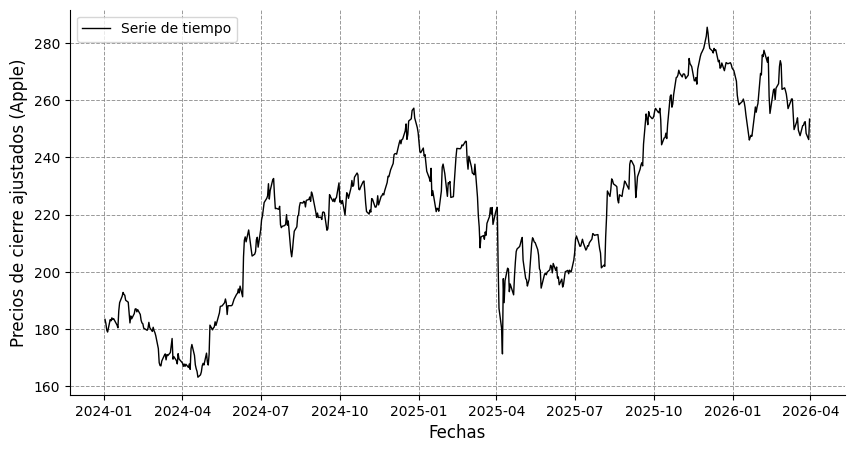

In [ ]:
# @title
import matplotlib.pyplot as plt

# --- Configuración general del gráfico ---
plt.figure(
    figsize=(10, 5),   # tamaño de la figura (ancho, alto) en pulgadas
    dpi=100           # resolución del gráfico
)

# --- Gráfico de línea ---
plt.plot(
    x, y,
    color='black',   # color de la línea
    linewidth=1.0,        # grosor de la línea
    linestyle='-',        # estilo de línea
    marker='o',           # marcador en cada punto
    markersize=0,         # tamaño del marcador
    markerfacecolor='white',
    markeredgecolor='black',
    label='Serie de tiempo'
)

# --- Título ---
plt.title(
    '',
    fontsize=14,
    fontweight='bold'
)

# --- Etiquetas de los ejes ---
plt.xlabel(
    'Fechas',
    fontsize=12
)

plt.ylabel(
    'Precios de cierre ajustados (Apple)',
    fontsize=12
)

# --- Fuente de los ticks ---
plt.xticks(fontsize=10)
plt.yticks(fontsize=10)

# --- Márgenes ---
plt.margins(x=0.05, y=0.05)  # espacio extra alrededor de los datos
plt.gca().spines['right'].set_visible(False) # derecha
plt.gca().spines['top'].set_visible(False)   # superior

# Para eliminar márgenes completamente, usar:
# plt.margins(0)

# --- Cuadrícula (opcional, pero didáctica) ---
plt.grid(
    visible=True,
    linestyle='--',
    linewidth=0.7,
    alpha=0.8,
    color="gray"
)

# --- Leyenda ---
plt.legend(
    fontsize=10,
    loc='best',
    frameon=True
)

